# Supplemental Figure 3, Panel D

Lineplots showing induction of expression in response to stimulus for both IFNg and Dex. For each stimulus, early (1h) and late (6h) induced gene sets are plotted as separate lines

*Output: PanelD_lineplot.pdf*

# Setup

In [2]:
# load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/SuppFig4/PanelD/PanelD.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [3]:
# load sample data (col.data), gene metadata (row.data) and table of TPMs

# TPMs
tpms <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "VST_abundance_batchCorr.tsv"
  ),
  sep = "\t"
)
# gene-level metadata
row.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "gene_metadata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "rsem_metadata.tsv"
  ),
  sep = "\t"
)


# read in differential expression analysis results

# stimulus vs vehicle
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "IFN_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "IFN_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "Dex_6h_DEGs.tsv"),
  sep = "\t"
)
#define 1h-induced and 6h-induced gene sets
ifn_up_1h <- (ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up")
sum(ifn_up_1h)
ifn_up_6h <-  (ifn_1h$change != "up" & ifn_6h$change == "up")
sum(ifn_up_6h)

dex_up_1h <- (dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up") 
sum(dex_up_1h)
dex_up_6h <- (dex_1h$change != "up" & dex_6h$change == "up")
sum(dex_up_6h)

[1] 61

[1] 134

[1] 45

[1] 308

# Scale and vehicle-normalize TPMs

In [17]:
#IFNy
#IFNy
col.data_ifn <- col.data[grep("IFN|Veh",col.data$condition),]
tpm_ifn <- tpms[,grep("IFN|Veh",col.data$condition)] %>% `colnames<-`(col.data_ifn$sample_id)


#average over replicates
tpm_ifn_mean <- tpm_ifn %>% mutate(id=row.data$gene_id_base) %>% 
    pivot_longer(!id) %>% 
    mutate(cond=sub("_r.$", "", name)) %>%
    group_by(id, cond) %>%
    summarize(value=mean(value), .groups="drop") %>%
    pivot_wider(names_from=cond) 
tpm_ifn_mean <- tpm_ifn_mean[match(row.data$gene_id_base, tpm_ifn_mean$id),] %>% select(!id)

#filter to only include IFNy-inducible genes
ifn_inducible <- rbind(tpm_ifn_mean[ifn_up_1h,],tpm_ifn_mean[ifn_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_ifn_inducible <- rbind(row.data[ifn_up_1h,],row.data[ifn_up_6h,]) %>% mutate(category=c(rep("up_1h", 61), rep("up_6h", 134)))

#select only IFNy-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
ifn_inducible_scale <- 
    ifn_inducible %>%
        mutate(Veh=(Veh_1h + Veh_6h)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1h, Veh_6h)) %>% 
        #+1 %>% log2() %>% 
        apply(MARGIN=1,FUN=scale) %>% t() %>%
        `colnames<-`(c('BAFinh_IFN_1h','BAFinh_IFN_6h','IFN_1h','IFN_6h', "Veh")) %>%
        data.frame()
ifn_inducible_scale <- ifn_inducible_scale[,-grep("BAFinh", colnames(ifn_inducible_scale))]
head(ifn_inducible_scale)



#Dex
#filter for only columns containing vehicle or Dex treatment
col.data_dex <- col.data[grep("Dex|Veh",col.data$condition),]
tpm_dex <- tpms[,grep("Dex|Veh",col.data$condition)] %>% `colnames<-`(col.data_dex$sample_id)


#average over replicates
tpm_dex_mean <- tpm_dex %>% mutate(id=row.data$gene_id_base) %>% 
    pivot_longer(!id) %>% 
    mutate(cond=sub("_r.$", "", name)) %>%
    group_by(id, cond) %>%
    summarize(value=mean(value), .groups="drop") %>%
    pivot_wider(names_from=cond) 
tpm_dex_mean <- tpm_dex_mean[match(row.data$gene_id_base, tpm_dex_mean$id),] %>% select(!id)

#filter to only include Dex-inducible genes
dex_inducible <- rbind(tpm_dex_mean[dex_up_1h,],tpm_dex_mean[dex_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_dex_inducible <- rbind(row.data[dex_up_1h,],row.data[dex_up_6h,]) %>% mutate(category=c(rep("up_1h", 45), rep("up_6h", 308)))

#select only Dex-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
dex_inducible_scale <- 
    dex_inducible %>%
        mutate(Veh=(Veh_1h + Veh_6h)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1h, Veh_6h)) %>% 
        #+1 %>% log2() %>% 
        apply(MARGIN=1,FUN=scale) %>% t() %>%
        `colnames<-`(c('BAFinh_Dex_1h','BAFinh_Dex_6h','Dex_1h','Dex_6h', "Veh")) %>%
        data.frame()
dex_inducible_scale <- dex_inducible_scale[,-grep("BAFinh", colnames(dex_inducible_scale))]
head(dex_inducible_scale)


,IFN_1h,IFN_6h,Veh
,<dbl>,<dbl>,<dbl>
1,0.6164509,1.4069226,-0.8876049
2,1.4949971,0.4526779,-0.2102065
3,0.5149458,1.5205275,-0.5792471
4,0.1308095,1.6790807,-0.7227129
5,1.0006079,0.8364583,0.1815604
6,1.3841367,0.6994257,-0.9551248


,Dex_1h,Dex_6h,Veh
,<dbl>,<dbl>,<dbl>
1,0.4849517,1.5300619,-0.6275489
2,1.2145322,0.8694371,-0.2587825
3,-0.1646468,1.5426472,-1.0667570
4,0.6376932,0.6625271,-0.9944199
5,0.5347035,0.2276020,-1.1475626
6,0.5421092,0.3113739,-1.7597061


# Generate plots

In [20]:
#generate lineplot - median with IQR
lineplot_ifn_median <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(time=ifelse(grepl("Veh", name), 0, gsub("h", "", gsub("^.*_","",name))))%>% 
    group_by(cat,time) %>% 
            summarize(name, median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75), .groups="drop") %>% #summarize data
    ggplot() +
        geom_hline(yintercept=0, linetype=2) + 
        geom_vline(xintercept=c(0,1,6), linetype=2) + 
        geom_ribbon(aes(x=as.numeric(time),ymin=pctile_25, ymax=pctile_75, fill=cat), alpha=.1) + 
        geom_line(aes(x=as.numeric(time),y=median, color=cat, group=cat), linewidth=1) +
        geom_point(aes(x=as.numeric(time),y=median, color=cat, group=cat), size=2) +
        ylab("Normalized expression") +
        xlab("IFNy treatment (h)") +
        scale_color_manual(values=c("#1c9e77", "#1c9e77")) +
        scale_fill_manual(values=c("#1c9e77", "#1c9e77"))  +
        ggtitle(paste("IFNy-inducible genes, n =", nrow(ifn_inducible_scale))) +
        scale_y_continuous(breaks=c(0,1,2))  +
        scale_x_continuous(breaks=c(0,1,6))

#generate lineplot - median with IQR
lineplot_dex_median <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(time=ifelse(grepl("Veh", name), 0, gsub("h", "", gsub("^.*_","",name))))%>% 
    group_by(cat,time) %>% 
            summarize(name, median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75), .groups="drop") %>% #summarize data
    ggplot() +
        geom_hline(yintercept=0, linetype=2) + 
        geom_vline(xintercept=c(0,1,6), linetype=2) + 
        geom_ribbon(aes(x=as.numeric(time),ymin=pctile_25, ymax=pctile_75, fill=cat), alpha=.1) + 
        geom_line(aes(x=as.numeric(time),y=median, color=cat, group=cat), linewidth=1) +
        geom_point(aes(x=as.numeric(time),y=median, color=cat, group=cat), size=2) +
        ylab("Normalized expression") +
        xlab("Dex treatment (h)") +
        scale_color_manual(values=c("#5791c9", "#5791c9")) +
        scale_fill_manual(values=c("#5791c9", "#5791c9"))  +
        ggtitle(paste("Dex-inducible genes, n =", nrow(dex_inducible_scale))) +
        scale_y_continuous(breaks=c(0,1,2))  +
        scale_x_continuous(breaks=c(0,1,6))

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


# Assemble figure panel

Saving 5 x 7 in image


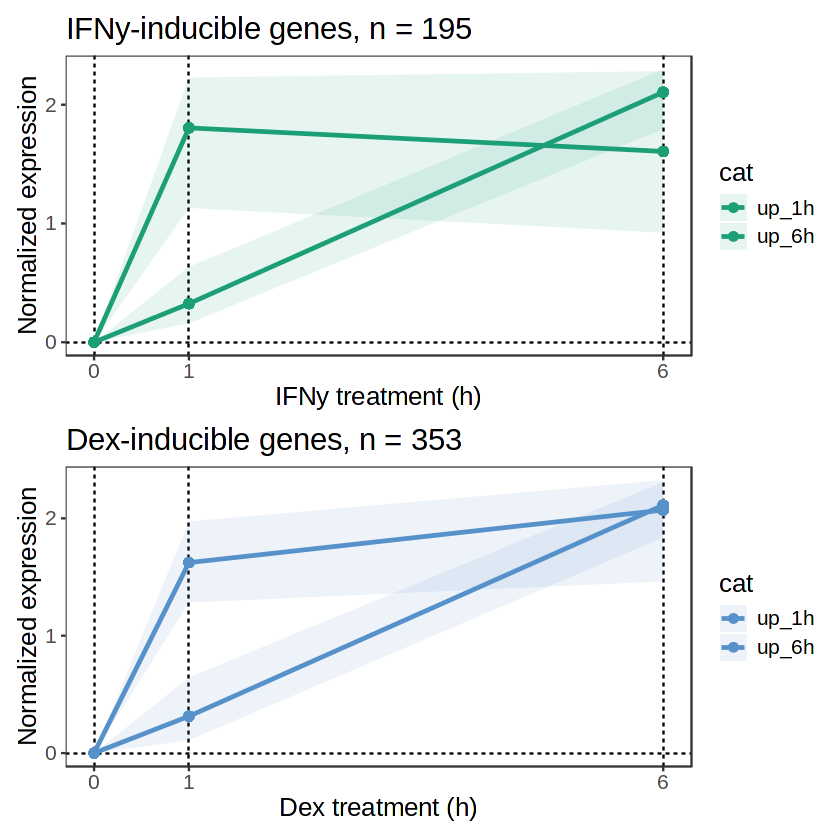

In [21]:
lineplot_ifn_median / lineplot_dex_median
ggsave("PanelD_lineplot.pdf", width=5)